# CampaignScore — Customer Segmentation

> **Case de Machine Learning | Etapa 03 — Segmentação de clientes**

## Contexto do case

O **CampaignScore** é um case de Machine Learning integrante do projeto **CRM Intelligence**, inspirado em um desafio de processo seletivo para Analista de Dados de CRM, proposto por uma empresa brasileira do segmento de delivery de alimentos.

O cenário do desafio representa uma empresa fictícia do varejo alimentício que busca melhorar a rentabilidade de suas campanhas de marketing direto. Uma campanha piloto, realizada com 2.240 clientes, apresentou taxa de conversão de aproximadamente 15%, gerando receita inferior ao custo da ação e um resultado financeiro negativo de 3.046 unidades monetárias (MU).

Esse resultado motivou a busca por uma abordagem orientada por dados, capaz de identificar clientes com maior propensão a aceitar ofertas e direcionar os esforços de marketing de maneira mais eficiente. **O objetivo central do case é desenvolver soluções analíticas que contribuam para maximizar a rentabilidade das campanhas.**

Os dados utilizados são públicos e representam o cenário fictício proposto no desafio, não correspondendo a registros reais de clientes da empresa que o inspirou.

## Objetivo desta etapa

Aplicar segmentação não supervisionada aos clientes, utilizando as 23 features selecionadas especificamente para essa finalidade no Notebook 02 — Feature Selection.

O objetivo é identificar grupos de clientes com características semelhantes de perfil, consumo, relacionamento, canais de compra e histórico de aceitação de campanhas, utilizando o algoritmo K-Means.

## Escopo e decisões da análise

- A análise utiliza o `SEGMENTATION_DATA`, contendo 23 features selecionadas para segmentação e `ID`, mantida exclusivamente para identificação e rastreabilidade dos clientes.
- As features são pré-processadas de acordo com seus tipos e distribuições, utilizando imputação, padronização, transformação Yeo-Johnson e codificação categórica. Os indicadores binários preservam a escala original de 0 e 1, sem padronização adicional.
- São avaliadas diferentes configurações de K, entre 2 e 10, utilizando métricas internas de agrupamento e a distribuição dos clientes entre os clusters.
- A configuração **K=3** é adotada para proporcionar maior granularidade na caracterização dos perfis, embora K=2 apresente melhores resultados nas métricas internas desta execução. A escolha prioriza a interpretabilidade dos segmentos, não uma superioridade estatística.
- Os clusters são caracterizados a partir das variáveis em suas unidades e categorias originais, permitindo interpretar os padrões de renda, consumo, relacionamento, canais de compra e histórico promocional.
- As análises dos segmentos possuem caráter descritivo e não estabelecem relações causais ou comprovam efetividade comercial. A escolha dos grupos deve ser entendida como uma representação de similaridade segundo as features e transformações utilizadas.

## Arquivos de saída

- **Atribuições dos segmentos em Parquet:** caminho definido por `SEGMENT_ASSIGNMENTS`, contendo a identificação dos clientes (`ID`), o cluster atribuído (`cluster_id`) e seu respectivo rótulo (`segment_label`).
- **Perfil dos segmentos em CSV:** caminho definido por `SEGMENT_PROFILE`, contendo a caracterização agregada dos clusters e seus principais indicadores.
- **Modelo de segmentação em Joblib:** pipeline contendo o pré-processador ajustado e o modelo K-Means treinado, permitindo reproduzir as transformações e realizar atribuições em novos registros.
- **Metadados em JSON:** parâmetros do modelo, features utilizadas, configurações de pré-processamento, distribuição dos clusters, métricas de referência e informações do ambiente de execução.

Os caminhos efetivos dos artefatos são centralizados no módulo `src.paths`.

## 1. Configuração e carregamento dos dados

O notebook consome o dataset apontado pela variável `SEGMENTATION_DATA`, produzido no Notebook 02 — Feature Selection do CampaignScore.

In [1]:
# Importação das bibliotecas e dos caminhos dos artefatos do projeto
import sys
sys.path.insert(0, "..")

import json
import platform
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

from src.paths import (
    SEGMENTATION_DATA,
    SEGMENT_ASSIGNMENTS,
    SEGMENT_PROFILE,
    SEGMENTATION_FOLDER,
)

In [2]:
# Definição dos parâmetros de execução e dos valores de K a avaliar
RANDOM_STATE = 42
N_INIT = 20
MAX_ITER = 300
K_VALUES = range(2, 11)
N_CLUSTERS = 3

In [3]:
# Configuração das opções de exibição e do padrão visual das análises
pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.linestyle": ":",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
    "axes.axisbelow": True,
})

### 1.1 Função auxiliar

A função `evaluate_kmeans()` avalia diferentes configurações do algoritmo K-Means, considerando valores distintos de K. Para cada configuração, calcula métricas internas de agrupamento — Inércia, Silhouette, Calinski-Harabasz e Davies-Bouldin — além do tamanho do menor cluster.

A função retorna uma tabela consolidada com os resultados, permitindo comparar as configurações avaliadas e subsidiar a decisão sobre a quantidade de segmentos.

In [4]:
# Avalia diferentes quantidades de clusters e consolida as métricas internas.
def evaluate_kmeans(
    matrix: pd.DataFrame | np.ndarray,
    k_values=range(2, 11),
    random_state: int = 42,
    n_init: int = 20,
    max_iter: int = 300,
) -> pd.DataFrame:
    """Avalia modelos K-Means para diferentes valores de K.

    Parameters
    ----------
    matrix : pd.DataFrame | np.ndarray
        Matriz numérica já pré-processada.
    k_values : iterable of int
        Quantidades de clusters que serão avaliadas.
    random_state : int
        Semente utilizada para a inicialização do K-Means.
    n_init : int
        Número de inicializações executadas para cada valor de K.
    max_iter : int
        Número máximo de iterações por inicialização.

    Returns
    -------
    pd.DataFrame
        Tabela com inércia, Silhouette, Calinski-Harabasz,
        Davies-Bouldin e tamanho do menor cluster para cada K.
    """
    values = np.asarray(matrix, dtype=float)
    results = []

    for k in k_values:
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            random_state=random_state,
            n_init=n_init,
            max_iter=max_iter,
        )
        labels = model.fit_predict(values)
        results.append({
            "k": k,
            "inertia": model.inertia_,
            "silhouette": silhouette_score(values, labels),
            "calinski_harabasz": calinski_harabasz_score(values, labels),
            "davies_bouldin": davies_bouldin_score(values, labels),
            "smallest_cluster": pd.Series(labels).value_counts().min(),
        })

    return pd.DataFrame(results)

### 1.2 Carregamento do Segmentation Data

O `SEGMENTATION_DATA`, produzido no Notebook 02 — Feature Selection do CampaignScore, reúne as 23 features selecionadas para a segmentação e a coluna `ID`, mantida exclusivamente para identificação e rastreabilidade dos clientes.

O arquivo é carregado em formato Parquet para utilização nas etapas de validação, pré-processamento e treinamento do modelo de segmentação.

In [5]:
# Carregamento do conjunto de dados destinado à segmentação
df = pd.read_parquet(SEGMENTATION_DATA)

display(df.head(3))
print(f"Formato do dataset: {df.shape[0]:,} linhas x {df.shape[1]} colunas")

,ID,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumStorePurchases,NumCatalogPurchases,NumDealsPurchases,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Kidhome,Teenhome,Age,Income,Education,TenureDays,Recency,NumWebVisitsMonth
0,5524,635,88,546,172,88,88,8,4,10,3,0,0,0,0,0,0,0,57,58138.0,Graduation,663,58,7
1,2174,11,1,6,2,1,6,1,2,1,2,0,0,0,0,0,1,1,60,46344.0,Graduation,113,38,5
2,4141,426,49,127,111,21,42,8,10,2,1,0,0,0,0,0,0,0,49,71613.0,Graduation,312,26,4


Formato do dataset: 2,229 linhas x 24 colunas


## 2. Seleção e validação das features

O conjunto recebido contém 24 colunas: 23 features destinadas à segmentação e o identificador `ID`, utilizado apenas para rastreabilidade.

In [6]:
# Features numéricas com padronização convencional.
standard_cols = [
    "Age",
    "Income",
    "Kidhome",
    "Teenhome",
    "Recency",
    "TenureDays",
]

# Features referentes às categorias de consumo.
spend_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
]

# Features referentes às compras por modalidade e canal.
purchase_cols = [
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
]

digital_cols = ["NumWebVisitsMonth"]
skewed_cols = spend_cols + purchase_cols + digital_cols

# Indicadores binários de aceitação de campanhas.
binary_cols = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
]

categorical_cols = ["Education"]

In [7]:
# Validação do inventário de features e construção da matriz de entrada
SEGMENTATION_FEATURES = (
    standard_cols
    + skewed_cols
    + binary_cols
    + categorical_cols
)

identifier_cols = ["ID"]

missing_declared = sorted(
    set(SEGMENTATION_FEATURES + identifier_cols) - set(df.columns)
)
unclassified_cols = sorted(
    set(df.columns) - set(SEGMENTATION_FEATURES) - set(identifier_cols)
)

if missing_declared:
    raise ValueError(f"Colunas declaradas ausentes no Segmentation Data: {missing_declared}")
if unclassified_cols:
    raise ValueError(f"Colunas sem classificação explícita: {unclassified_cols}")

assert len(SEGMENTATION_FEATURES) == 23
assert len(set(SEGMENTATION_FEATURES)) == 23
assert df["ID"].is_unique

X = df[SEGMENTATION_FEATURES].copy()
X[categorical_cols] = X[categorical_cols].astype("object")

print(f"Colunas recebidas: {df.shape[1]}")
print(f"Features utilizadas: {len(SEGMENTATION_FEATURES)}")
print(f"Colunas fora da matriz: {len(identifier_cols)}")
print(f"Dimensão da matriz X: {X.shape}")

Colunas recebidas: 24
Features utilizadas: 23
Colunas fora da matriz: 1
Dimensão da matriz X: (2229, 23)


### 2.1. Auditoria das features

Antes do pré-processamento, são verificadas as ausências, as categorias de `Education` e a distribuição dos indicadores binários. As flags de campanhas devem conter somente `0` e `1` nos valores observados; eventuais valores ausentes são tratados posteriormente pela imputação.

In [8]:
# Identificação dos valores ausentes nas features de entrada
missing = X.isna().sum()
missing = missing[missing > 0]

print("Valores ausentes nas features:")

if missing.empty:
    print("Nenhum valor ausente.")
else:
    display(missing.rename("missing").to_frame())

Valores ausentes nas features:


,missing
Income,24


In [9]:
# Inspeção da distribuição da variável categórica Education
display(X["Education"].value_counts(dropna=False).rename("customers").to_frame())

,customers
Education,
Graduation,1124
PhD,481
Master,369
2n Cycle,201
Basic,54


In [10]:
# Valida o domínio das flags binárias e resume suas frequências.
invalid_binary_values = {
    column: sorted(X[column].dropna().unique().tolist(), key=str)
    for column in binary_cols
    if not X[column].dropna().isin([0, 1]).all()
}

if invalid_binary_values:
    raise ValueError(
        f"Valores diferentes de 0 e 1 encontrados nas flags: {invalid_binary_values}"
    )

binary_audit = pd.DataFrame({
    "zeros": X[binary_cols].eq(0).sum(),
    "ones": X[binary_cols].eq(1).sum(),
    "positive_rate_%": X[binary_cols].mean() * 100,
})

display(binary_audit.round(2))

,zeros,ones,positive_rate_%
AcceptedCmp1,2085,144,6.46
AcceptedCmp2,2199,30,1.35
AcceptedCmp3,2066,163,7.31
AcceptedCmp4,2062,167,7.49
AcceptedCmp5,2067,162,7.27


## 3. Pré-processamento

Como o K-Means utiliza distâncias, as features são tratadas conforme seus tipos e distribuições:

- **Numéricas convencionais:** imputação pela mediana e `StandardScaler`.
- **Numéricas assimétricas:** imputação pela mediana e transformação Yeo-Johnson com padronização.
- **Flags binárias:** imputação pela moda, preservando os valores 0 e 1, sem padronização adicional.
- **Categórica:** imputação pela moda e One-Hot Encoding.

A preservação das flags em escala binária mantém sua interpretação original, mas também significa que sua contribuição para a distância euclidiana ocorre nessa escala, sem ponderação adicional. Essa é uma decisão de representação adotada nesta segmentação.

O pré-processador é ajustado sobre a base utilizada nesta segmentação. O objeto ajustado será preservado junto com o K-Means para permitir a aplicação consistente do mesmo tratamento a novos registros.

In [11]:
# Definição dos pipelines de transformação para cada grupo de features
numeric_standard_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

numeric_skewed_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("power", PowerTransformer(method="yeo-johnson", standardize=True)),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

binary_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("standard", numeric_standard_pipeline, standard_cols),
        ("power", numeric_skewed_pipeline, skewed_cols),
        ("categorical", categorical_pipeline, categorical_cols),
        ("binary", binary_pipeline, binary_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
)

# Configura a saída Pandas antes do ajuste dos transformadores.
preprocessor.set_output(transform="pandas")

# Ajusta o pré-processamento e gera a matriz transformada.
X_processed = preprocessor.fit_transform(X)


In [12]:
# Verificação da dimensionalidade e integridade da matriz transformada
print(f"Features de entrada: {X.shape[1]}")
print(f"Dimensões após pré-processamento: {X_processed.shape[1]}")
print(f"Matriz final: {X_processed.shape}")

assert isinstance(X_processed, pd.DataFrame)
assert X_processed.shape == (len(X), 27)
assert X_processed.isna().sum().sum() == 0
assert np.isfinite(X_processed.to_numpy(dtype=float)).all()

assert list(X_processed.columns) == list(
    preprocessor.get_feature_names_out()
)


Features de entrada: 23
Dimensões após pré-processamento: 27
Matriz final: (2229, 27)


### 3.1. Dimensionalidade após a transformação

As 23 features de entrada resultam em **27 dimensões transformadas**: seis numéricas padronizadas, onze numéricas transformadas, cinco indicadores binários e cinco colunas geradas pelo One-Hot Encoding de `Education`. A expansão da variável categórica evita impor uma ordem artificial às categorias.

## 4. Avaliação do número de clusters

São avaliados valores de K entre 2 e 10 por meio de quatro métricas:

- **Inércia:** auxilia a observar o ponto de inflexão; diminui com o aumento de K.
- **Silhouette:** combina coesão e separação; valores maiores tendem a ser melhores.
- **Calinski-Harabasz:** valores maiores tendem a indicar maior separação relativa.
- **Davies-Bouldin:** valores menores tendem a indicar grupos mais compactos e separados.

As métricas são consideradas em conjunto com o tamanho e a utilidade interpretativa dos segmentos.

In [13]:
# Avaliação dos valores de K e consolidação das métricas
kmeans_metrics = evaluate_kmeans(
    X_processed,
    k_values=K_VALUES,
    random_state=RANDOM_STATE,
    n_init=N_INIT,
    max_iter=MAX_ITER,
)

display(kmeans_metrics.round(4))

,k,inertia,silhouette,calinski_harabasz,davies_bouldin,smallest_cluster
0,2,26682.8991,0.2864,1110.7152,1.3806,1068
1,3,23188.1751,0.2133,806.5112,1.7529,664
2,4,21807.3401,0.1551,618.4249,2.0759,413
3,5,20670.8479,0.1305,519.6688,2.2536,356
4,6,19888.9138,0.1289,449.3649,2.2194,263
5,7,19326.7184,0.1180,395.9630,2.3475,246
6,8,18816.4929,0.1115,357.0465,2.3019,209
7,9,18383.3098,0.1043,326.1724,2.3678,140
8,10,17997.0969,0.1023,301.3105,2.3161,142


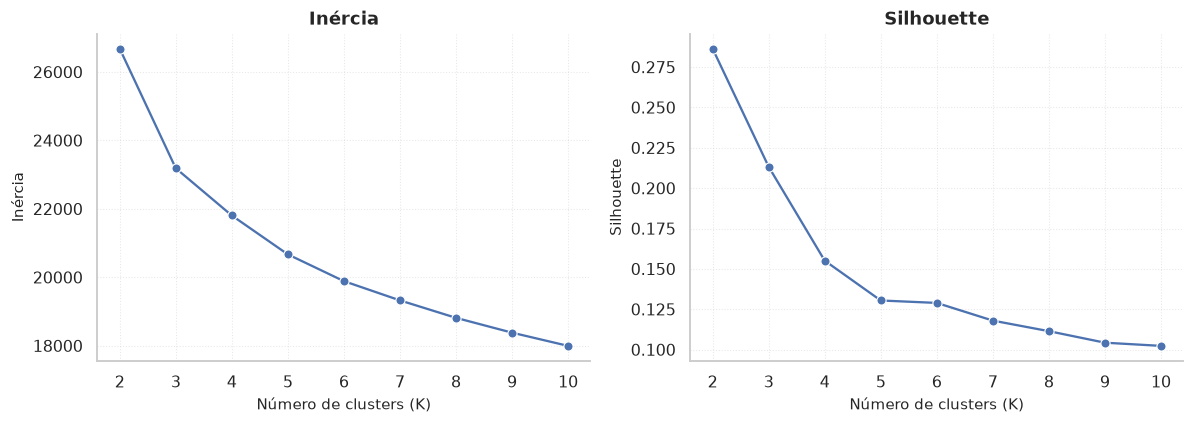

In [14]:
# Visualização da inércia e da Silhouette em função do número de clusters
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.lineplot(data=kmeans_metrics, x="k", y="inertia", marker="o", ax=axes[0])
axes[0].set_title("Inércia")
axes[0].set_xlabel("Número de clusters (K)")
axes[0].set_ylabel("Inércia")
axes[0].set_xticks(kmeans_metrics["k"])

sns.lineplot(data=kmeans_metrics, x="k", y="silhouette", marker="o", ax=axes[1])
axes[1].set_title("Silhouette")
axes[1].set_xlabel("Número de clusters (K)")
axes[1].set_ylabel("Silhouette")
axes[1].set_xticks(kmeans_metrics["k"])

plt.tight_layout()
plt.show()

### 4.1. Decisão de granularidade

As métricas internas favoreceram K=2 nesta execução, apresentando os melhores resultados de Silhouette, Calinski-Harabasz e Davies-Bouldin. Portanto, K=3 não foi selecionado por superioridade estatística nessas métricas.

Ainda assim, K=3 foi mantido como configuração de trabalho por permitir a caracterização de três perfis distintos, com tamanhos relevantes e participação relativamente distribuída: 40,11%, 30,10% e 29,79% da base.

A decisão prioriza maior granularidade para a interpretação dos padrões de consumo e relacionamento. Os perfis observados ajudam a descrever essa configuração, mas não demonstram, por si só, que três segmentos gerem maior efetividade comercial do que uma solução com K=2. A escolha deve ser entendida como um compromisso analítico entre qualidade interna e nível de detalhamento desejado.

In [15]:
# Ajuste do K-Means com a granularidade selecionada
kmeans_model = KMeans(
    n_clusters=N_CLUSTERS,
    init="k-means++",
    random_state=RANDOM_STATE,
    n_init=N_INIT,
    max_iter=MAX_ITER,
)

cluster_ids = kmeans_model.fit_predict(X_processed)

df_segmented = df.copy()
df_segmented["cluster_id"] = cluster_ids


In [16]:
# Cálculo da quantidade e participação de clientes em cada cluster
cluster_counts = (
    df_segmented["cluster_id"]
    .value_counts()
    .sort_index()
    .rename("customers")
    .to_frame()
)

cluster_counts["share_pct"] = (
    cluster_counts["customers"] / len(df_segmented) * 100
)

display(cluster_counts.round(2))

,customers,share_pct
cluster_id,,
0,894,40.11
1,671,30.10
2,664,29.79


## 5. Interpretação dos clusters

A interpretação utiliza as variáveis disponíveis no Segmentation Data, apresentadas em suas unidades e categorias originais. A caracterização considera os indicadores numéricos, a composição educacional e o histórico de aceitação das campanhas anteriores.

As médias de `Income` são calculadas somente sobre os registros com renda disponível. Os valores ausentes permanecem ausentes na base utilizada para a caracterização e não são substituídos pelos valores imputados na matriz transformada para o K-Means.

As análises são descritivas: ajudam a compreender as diferenças entre os grupos, mas não estabelecem relações causais.

In [17]:
# Caracterização numérica dos clusters nas unidades originais
profile_numeric_cols = standard_cols + skewed_cols

cluster_numeric_profile = (
    df_segmented.groupby("cluster_id")[profile_numeric_cols]
    .agg(["mean", "median"])
)

display(cluster_numeric_profile.round(2))

Age           Income          Kidhome        Teenhome         \
             mean median      mean   median    mean median     mean median   
cluster_id                                                                   
0           41.82   41.0  32506.29  32880.0    0.82    1.0     0.42    0.0   
1           45.78   45.0  73863.05  74293.0    0.04    0.0     0.24    0.0   
2           48.87   49.0  54675.83  55158.0    0.35    0.0     0.90    1.0   

           Recency        TenureDays        MntWines        MntFruits         \
              mean median       mean median     mean median      mean median   
cluster_id                                                                     
0            48.40   49.0     314.73  301.5    27.98   16.0      3.82    2.0   
1            49.51   52.0     346.41  343.0   581.04  532.0     64.40   50.0   
2            49.65   51.0     413.80  444.5   399.00  311.0     18.23    9.0   

           MntMeatProducts        MntFishProducts        MntSweetProducts  \
                      mean median            mean median             mean   
cluster_id                                                                  
0                    20.02   12.0            5.39    3.0             4.55   
1                   405.07  380.0           93.79   78.0            65.98   
2                   118.55   89.0           24.33   12.0            18.38   

                  MntGoldProds        NumDealsPurchases         \
           median         mean median              mean median   
cluster_id                                                       
0             2.0        12.94    8.0              1.89    2.0   
1            51.0        75.12   55.0              1.29    1.0   
2            10.0        54.75   37.0              3.93    4.0   

           NumWebPurchases        NumCatalogPurchases         \
                      mean median                mean median   
cluster_id                                                     
0                     1.89    2.0                0.43    0.0   
1                     5.22    5.0                5.54    5.0   
2                     5.95    6.0                2.67    2.0   

           NumStorePurchases        NumWebVisitsMonth         
                        mean median              mean median  
cluster_id                                                    
0                       2.96    3.0              6.52    7.0  
1                       8.50    8.0              2.93    3.0  
2                       6.94    6.0              6.16    6.0

In [18]:
# Cálculo da composição educacional de cada cluster
education_profile = pd.crosstab(
    df_segmented["cluster_id"],
    df_segmented["Education"],
    normalize="index",
) * 100

display(education_profile.round(2))

Education,2n Cycle,Basic,Graduation,Master,PhD
cluster_id,,,,,
0,10.63,5.82,48.21,15.77,19.57
1,9.24,0.00,54.84,15.05,20.86
2,6.63,0.30,48.95,19.13,25.00


In [19]:
# Cálculo das taxas de aceitação de campanhas por cluster
campaign_profile = (
    df_segmented.groupby("cluster_id")[binary_cols]
    .mean() * 100
)

display(campaign_profile.round(2))

,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5
cluster_id,,,,,
0,0.11,0.22,6.82,1.23,0.00
1,17.73,2.38,7.60,11.33,22.06
2,3.61,1.81,7.68,12.05,2.11


#### Síntese e caracterização dos clusters

A segmentação com K=3 identificou três grupos com diferenças relevantes de renda, consumo e comportamento de compra. As principais distinções estão no volume de gastos, na utilização dos canais comerciais, na frequência de compras com desconto e no histórico de aceitação das campanhas.

| Cluster | Perfil | Participação | Renda média (MU) | Consumo médio (MU) |
|---|---|---:|---:|---:|
| 0 | Baixo consumo | 40,11% | 32.506 | 74,69 |
| 1 | Alto consumo multicanal | 30,10% | 73.863 | 1.285,40 |
| 2 | Consumo intermediário orientado a ofertas | 29,79% | 54.676 | 633,24 |

*Consumo médio corresponde à soma dos gastos médios nas seis categorias de produtos. A renda média considera somente as observações com `Income` disponível.*

**Cluster 0 — Baixo consumo**

Representando 40,11% da base, concentra clientes com menor renda e consumo médio. Também apresenta baixa frequência de compras nos diferentes canais. Apesar da menor atividade comercial, registra a maior média de visitas mensais ao site (6,52), sugerindo uma distância entre o interesse digital e a efetivação das compras.

No histórico de campanhas, apresenta baixa aceitação, especialmente nas campanhas 1, 2, 4 e 5. Na escolaridade, possui a maior participação da categoria Basic (5,82%), embora Graduation continue predominante (48,21%).

**Cluster 1 — Alto consumo multicanal**

Com 30,10% dos clientes, reúne o grupo de maior renda e consumo médio. Apresenta também a maior frequência de compras em lojas físicas (8,50) e por catálogo (5,54), além de participação expressiva nas compras pela web (5,22).

Destaca-se pela menor frequência de compras com desconto (1,29) e de visitas mensais ao site (2,93). No histórico de campanhas, apresenta as maiores taxas de aceitação nas campanhas 1 (17,73%) e 5 (22,06%), além de participação relevante na campanha 4 (11,33%). Em escolaridade, possui a maior concentração de Graduation (54,84%) e não registra clientes na categoria Basic.

**Cluster 2 — Consumo intermediário orientado a ofertas**

Representando 29,79% da base, apresenta renda e consumo médios intermediários entre os outros grupos. Seu comportamento comercial é marcado pela maior frequência de compras pela web (5,95) e de compras com desconto (3,93), além de uma média de 6,16 visitas mensais ao site.

No histórico de campanhas, apresenta a maior participação relativa na campanha 4 (12,05%), enquanto a aceitação das campanhas 1 e 5 é inferior à observada no Cluster 1. Na escolaridade, destaca-se pela participação de clientes com PhD (25,00%) e Master (19,13%), embora Graduation também seja predominante (48,95%).

## 6. Exportação dos resultados

São produzidos dois artefatos de dados: o perfil agregado dos segmentos, com uma linha por cluster, e a atribuição operacional, com uma linha por cliente.

### 6.1. Atribuição dos clientes aos segmentos

In [20]:
# Atribuição dos rótulos descritivos e identificação individual dos clientes
SEGMENT_LABELS = {
    0: "Baixo consumo",
    1: "Alto consumo multicanal",
    2: "Consumo intermediário orientado a ofertas",
}

segmentation_assignments = df_segmented[["ID"]].copy()
segmentation_assignments["cluster_id"] = cluster_ids
segmentation_assignments["segment_label"] = (
    segmentation_assignments["cluster_id"].map(SEGMENT_LABELS)
)

assert segmentation_assignments["ID"].is_unique
assert segmentation_assignments["segment_label"].notna().all()
assert len(segmentation_assignments) == len(df)

display(segmentation_assignments.head())

,ID,cluster_id,segment_label
0,5524,1,Alto consumo multicanal
1,2174,0,Baixo consumo
2,4141,1,Alto consumo multicanal
3,6182,0,Baixo consumo
4,5324,2,Consumo intermediário orientado a ofertas


### 6.2. Perfil agregado dos segmentos

O perfil contém o tamanho e a participação de cada grupo, indicadores de renda, consumo, relacionamento e canais de compra, além das taxas observadas de aceitação das campanhas e da composição educacional. `TotalSpend` é calculada apenas para caracterização e não integra a matriz utilizada pelo K-Means.

In [21]:
# Construção do perfil agregado dos segmentos a partir das variáveis originais
profile_source = df_segmented.copy()
profile_source["TotalSpend"] = profile_source[spend_cols].sum(axis=1)

segment_counts = (
    profile_source.groupby("cluster_id")
    .size()
    .rename("customer_count")
    .to_frame()
)
segment_counts["customer_share_pct"] = (
    segment_counts["customer_count"] / len(profile_source) * 100
)
segment_counts["segment_label"] = pd.Series(SEGMENT_LABELS)

numeric_profile = (
    profile_source.groupby("cluster_id")
    .agg(
        avg_age=("Age", "mean"),
        avg_income=("Income", "mean"),
        avg_total_spend=("TotalSpend", "mean"),
        median_total_spend=("TotalSpend", "median"),
        avg_recency_days=("Recency", "mean"),
        avg_tenure_days=("TenureDays", "mean"),
        avg_kidhome=("Kidhome", "mean"),
        avg_teenhome=("Teenhome", "mean"),
        avg_web_purchases=("NumWebPurchases", "mean"),
        avg_store_purchases=("NumStorePurchases", "mean"),
        avg_catalog_purchases=("NumCatalogPurchases", "mean"),
        avg_deal_purchases=("NumDealsPurchases", "mean"),
        avg_web_visits_month=("NumWebVisitsMonth", "mean"),
    )
)

campaign_profile_export = (
    profile_source.groupby("cluster_id")[binary_cols]
    .mean()
    .mul(100)
)
campaign_profile_export.columns = [
    f"{column.lower()}_pct" for column in campaign_profile_export.columns
]

education_profile_export = (
    pd.crosstab(
        profile_source["cluster_id"],
        profile_source["Education"],
        normalize="index",
    )
    .mul(100)
    .fillna(0)
)
education_profile_export.columns = [
    f"education_{str(column).strip().lower().replace(' ', '_')}_pct"
    for column in education_profile_export.columns
]

segment_profile = (
    segment_counts
    .join(numeric_profile)
    .join(campaign_profile_export)
    .join(education_profile_export)
    .reset_index()
)

profile_columns = (
    ["cluster_id", "segment_label", "customer_count", "customer_share_pct"]
    + numeric_profile.columns.tolist()
    + campaign_profile_export.columns.tolist()
    + education_profile_export.columns.tolist()
)
segment_profile = segment_profile[profile_columns]

display(segment_profile.round(2))

,cluster_id,segment_label,customer_count,customer_share_pct,avg_age,avg_income,avg_total_spend,median_total_spend,avg_recency_days,avg_tenure_days,avg_kidhome,avg_teenhome,avg_web_purchases,avg_store_purchases,avg_catalog_purchases,avg_deal_purchases,avg_web_visits_month,acceptedcmp1_pct,acceptedcmp2_pct,acceptedcmp3_pct,acceptedcmp4_pct,acceptedcmp5_pct,education_2n_cycle_pct,education_basic_pct,education_graduation_pct,education_master_pct,education_phd_pct
0,0,Baixo consumo,894,40.11,41.82,32506.29,74.69,55.0,48.40,314.73,0.82,0.42,1.89,2.96,0.43,1.89,6.52,0.11,0.22,6.82,1.23,0.00,10.63,5.82,48.21,15.77,19.57
1,1,Alto consumo multicanal,671,30.10,45.78,73863.05,1285.40,1253.0,49.51,346.41,0.04,0.24,5.22,8.50,5.54,1.29,2.93,17.73,2.38,7.60,11.33,22.06,9.24,0.00,54.84,15.05,20.86
2,2,Consumo intermediário orientado a ofertas,664,29.79,48.87,54675.83,633.24,523.0,49.65,413.80,0.35,0.90,5.95,6.94,2.67,3.93,6.16,3.61,1.81,7.68,12.05,2.11,6.63,0.30,48.95,19.13,25.00


### 6.3. Exportação dos artefatos de dados

In [22]:
# Criação dos diretórios e exportação dos artefatos de dados
SEGMENT_PROFILE.parent.mkdir(parents=True, exist_ok=True)
SEGMENT_ASSIGNMENTS.parent.mkdir(parents=True, exist_ok=True)

segment_profile.to_csv(
    SEGMENT_PROFILE,
    index=False,
    encoding="utf-8-sig",
)

segmentation_assignments.to_parquet(
    SEGMENT_ASSIGNMENTS,
    index=False,
)

print("Artefatos de dados exportados:")
print(f"Segment Profile: {SEGMENT_PROFILE}")
print(f"Segment Assignments: {SEGMENT_ASSIGNMENTS}")

Artefatos de dados exportados:
Segment Profile: /home/jhonathan/SDL/campaignscore/reports/customer_segment_profile.csv
Segment Assignments: /home/jhonathan/SDL/campaignscore/data/processed/customer_segment_assignments.parquet


### 6.4. Empacotamento e exportação do modelo

O artefato do modelo reúne o pré-processador ajustado e o K-Means treinado. Assim, novos registros poderão receber o mesmo tratamento e ser atribuídos aos segmentos sem reajustar o modelo.

In [23]:
# Empacotamento do pré-processador e do K-Means em um único pipeline
segmentation_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("kmeans", kmeans_model),
    ]
)

SEGMENTATION_FOLDER.mkdir(parents=True, exist_ok=True)

model_path = SEGMENTATION_FOLDER / "kmeans_v1.joblib"

joblib.dump(
    segmentation_model,
    model_path,
    compress=3,
)

['/home/jhonathan/SDL/campaignscore/models/segmentation/kmeans_v1.joblib']

### 6.5. Registro da configuração do modelo

O arquivo JSON documenta as features, os grupos de pré-processamento, os parâmetros do K-Means, os rótulos dos segmentos, os resultados de referência e as versões das bibliotecas utilizadas.

In [24]:
# Recuperação das métricas de referência e da distribuição dos clusters
model_metrics = kmeans_metrics.loc[
    kmeans_metrics["k"] == N_CLUSTERS
].iloc[0]

cluster_distribution = (
    segmentation_assignments["cluster_id"]
    .value_counts()
    .sort_index()
)

In [25]:
# Consolidação dos parâmetros, features e metadados da execução
segmentation_config = {
    "model_name": "customer_segmentation_kmeans",
    "artifact_version": "1.0.0",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "input": {
        "dataset": str(SEGMENTATION_DATA),
        "identifier_column": "ID",
        "features": SEGMENTATION_FEATURES,
        "feature_groups": {
            "standard": standard_cols,
            "skewed": skewed_cols,
            "binary": binary_cols,
            "categorical": categorical_cols,
        },
    },
    "preprocessing": {
        "standard": ["SimpleImputer(strategy='median')", "StandardScaler()"],
        "skewed": [
            "SimpleImputer(strategy='median')",
            "PowerTransformer(method='yeo-johnson', standardize=True)",
        ],
        "categorical": [
            "SimpleImputer(strategy='most_frequent')",
            "OneHotEncoder(handle_unknown='ignore', sparse_output=False)",
        ],
        "binary": ["SimpleImputer(strategy='most_frequent')"],
    },
    "algorithm": {
        "name": "KMeans",
        "parameters": {
            "n_clusters": int(kmeans_model.n_clusters),
            "init": str(kmeans_model.init),
            "n_init": int(kmeans_model.n_init),
            "max_iter": int(kmeans_model.max_iter),
            "random_state": int(kmeans_model.random_state),
            "tol": float(kmeans_model.tol),
            "algorithm": str(kmeans_model.algorithm),
        },
    },
    "output": {
        "cluster_column": "cluster_id",
        "label_column": "segment_label",
        "cluster_labels": {str(key): value for key, value in SEGMENT_LABELS.items()},
    },
    "training": {
        "n_samples": int(len(X)),
        "input_dimensions": int(X.shape[1]),
        "transformed_dimensions": int(X_processed.shape[1]),
        "cluster_distribution": {
            str(key): int(value) for key, value in cluster_distribution.items()
        },
        "reference_metrics": {
            "silhouette": float(model_metrics["silhouette"]),
            "calinski_harabasz": float(model_metrics["calinski_harabasz"]),
            "davies_bouldin": float(model_metrics["davies_bouldin"]),
            "inertia": float(model_metrics["inertia"]),
        },
    },
    "environment": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
}

In [26]:
# Exportação dos metadados de configuração do modelo em JSON
metadata_path = model_path.with_suffix(".metadata.json")

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(
        segmentation_config,
        file,
        ensure_ascii=False,
        indent=4
    )


### 6.6. Verificação de reprodutibilidade do modelo

O teste final recarrega o pipeline persistido, aplica o pré-processamento e reproduz as atribuições para a mesma base utilizada no ajuste. A comparação com os rótulos originais verifica se o modelo exportado mantém o comportamento observado durante o treinamento.

Esta verificação testa a reprodutibilidade das atribuições do pipeline; não realiza uma auditoria de existência ou de estrutura dos arquivos CSV e Parquet.

In [27]:
# Recarrega o modelo persistido.
loaded_model = joblib.load(model_path)

# Reproduz as atribuições dos clientes na mesma base.
labels_reloaded = loaded_model.predict(
    X[SEGMENTATION_FEATURES]
)

np.testing.assert_array_equal(
    labels_reloaded,
    cluster_ids,
)

print("Modelo exportado e validado.")

Modelo exportado e validado.


## 7. Conclusão

A segmentação não supervisionada foi aplicada a **2.229 clientes**, utilizando 23 features selecionadas para essa finalidade. O pré-processamento contemplou imputação, padronização, transformação Yeo-Johnson e codificação categórica, resultando em uma matriz de 27 dimensões para o K-Means.

Após a avaliação de diferentes valores de K, foram definidos três segmentos: **Baixo consumo** (40,11%), **Alto consumo multicanal** (30,10%) e **Consumo intermediário orientado a ofertas** (29,79%). A configuração K=3 foi escolhida para oferecer maior granularidade à caracterização dos clientes, embora K=2 tenha apresentado melhores métricas internas nesta execução.

Os perfis diferenciam-se principalmente por renda, volume de consumo, frequência e canais de compra. O histórico de aceitação de campanhas e a composição educacional complementam a caracterização. As médias de renda apresentadas nos perfis consideram apenas os registros com valores disponíveis.

Como resultado, foram produzidos os arquivos de atribuição individual dos clientes, perfil agregado dos segmentos, pipeline com pré-processamento e K-Means integrados e metadados da configuração utilizada.

Os clusters representam grupos de similaridade definidos pelas features e transformações adotadas. As diferenças observadas são descritivas e não estabelecem relações causais nem garantem resultados comerciais. A escolha de três segmentos representa uma decisão de granularidade analítica, não uma superioridade estatística sobre as demais configurações avaliadas.